# Crumblr — compositional differential abundance (HD Handsaker, village)

**Question:** does the cell-type composition of the striatum change in HD (Case) vs Control donors?

**Method: crumblr** (Hoffman lab):
1. Count the cells of each category per donor (category = a cell type, a zone, …).
2. Take the **CLR** (centred log-ratio) of the counts per donor: `log(count / geometric mean of all counts of that donor)`.
   This removes the compositional constraint (proportions sum to 1), so each category can be tested on its own.
3. Each CLR value gets a **precision weight** (few cells → noisy → low weight).
4. Fit a weighted linear model per category with limma.

**Model (one per category):**

```
CLR(category) ~ Status + Sex + Age + village
```

- tested coefficient: **`StatusCase`** (reference = Control) → `logFC` = change in CLR in Case vs Control
- `Sex`, `Age`, `village` = donor-level covariates (same as `Handsaker_DEG_factors.ipynb`)
- no random effect: after aggregation there is 1 row per donor, so crumblr uses `limma::lmFit` (not `dream`)

**Analyses run:**

| Section | Cells used | Categories tested |
|---|---|---|
| A | all cells | `ct_for_deg`, one zone-split column per zonable cell type, `Class_name`, `Subclass_name`, `Group_name` |
| B | neurons only | `ct_for_deg`, `Class_name`, `Subclass_name`, `Group_name` |
| C | all cells | all zonable cell types split by zone at the same time (one run) |
| D | one zonable cell type at a time | its zones (does the zone distribution *within* that cell type change?) |
| E | — | summary volcano plots |

**Setup (one-time):** `bash /home/gdallagl/myworkdir/XDP/data/crumblr/crumblr/setup_env.sh`
**Kernel:** any env with `scanpy` + `pandas`. crumblr itself runs in its own venv + R env through a subprocess (`run_workflow.py`).

## 0. Imports and configuration

Every parameter of the analysis is set here.

In [15]:
%load_ext autoreload
%autoreload 2

import os, re, sys, subprocess, traceback
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from adjustText import adjust_text
from IPython.display import display

from utils import preprocessing                                    # custom_palette for the UMAPs

sys.path.insert(0, "/home/gdallagl/myworkdir/XDP/data/crumblr")    # folder that contains plot_crumblr.py
from plot_crumblr import plot_all                                  # per-run plots (volcano, boxplots, ...)

# ── Paths ─────────────────────────────────────────────────────────────────────
ADATA          = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad"
SAVE_FOLDER    = "/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/compositional/crumblr"
CRUMBLR_SCRIPT = "/home/gdallagl/myworkdir/XDP/data/crumblr/crumblr/run_workflow.py"
DATASET_LABEL  = "HD Handsaker (village)"      # used in plot titles

# ── Study design ──────────────────────────────────────────────────────────────
SAMPLE_COL     = "DONOR"                        # 1 sample = 1 donor (each donor sits in exactly one village)
CONTRAST_COL   = "Status"
CONTRAST_REF   = "Control"
CONTRAST_STIM  = "Case"                         # tested coefficient = "StatusCase"
FIXED_EFFECTS  = ["Sex", "Age", "village"]      # donor-level covariates, same as Handsaker_DEG_factors.ipynb
RANDOM_EFFECTS = []                             # none: 1 row per donor after aggregation → limma lmFit

# ── Cell / donor filtering ────────────────────────────────────────────────────
CT_COL           = "ct_for_deg"                 # curated cell-type label
BAD_LABEL_PREFIX = "-"                          # labels starting with "-" are not real cell types (-Low_quality, -Phase_D, -Unassigned, ...)
AGE_CENSORED     = ">89"                        # these donors are dropped so that Age can be numeric (as in the DEG notebook)
VILLAGE_FROM_COL = "reaction"                   # "Village1_rxn3" → village = "Village1"

# ── Rare-category filters (applied before every crumblr run) ──────────────────
# (1) in this notebook: a category is kept only if it has >= MIN_CELLS_PER_DONOR_CT cells in >= MIN_DONORS_PER_CT donors
MIN_DONORS_PER_CT      = 5
MIN_CELLS_PER_DONOR_CT = 3
# (2) inside run_workflow.py
MIN_CELLS_PER_CATEGORY = 150    # --min-n-cells-category: categories with fewer cells in total (all donors) are dropped
MIN_CELLS_PER_DONOR    = 30     # --min-n-cells: donors with fewer cells in total (summed over the categories of the run) are dropped

# ── Annotation levels ─────────────────────────────────────────────────────────
ATLAS_LEVELS = ["Class_name", "Subclass_name", "Group_name"]   # MapMyCells labels

# Zonable cell types: ct_for_deg label → zone column used to split it
#   "zone"   = 6 zones, mapped with the Matrix MSN references
#   "zone_4" = 4 zones, mapped with the Patch / Astrocyte / D1D2-hybrid references
ZONE_CT_MAP = {
    "Matrix_D1": "zone",
    "Matrix_D2": "zone",
    "Patch_D1":  "zone_4",
    "Patch_D2":  "zone_4",
    "eMSN_D1D2": "zone_4",
    "Astrocyte": "zone_4",
}

# ── Summary volcano plots ─────────────────────────────────────────────────────
FDR_THR        = 0.05
LFC_THR        = 0.5
FORCE_LABEL_CT = ["eMSN_D1D2", "eMSN_NUDAP", "eMSN_StrioMat"]   # always labelled in the ct_for_deg volcano

os.makedirs(SAVE_FOLDER, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load the cell metadata

The h5ad is ~42 GB because of the expression matrix (`X` + layers). crumblr only needs **cell metadata** (`obs`),
so only `obs` and the UMAP coordinates (for the sanity-check plots) are loaded into memory.

In [16]:
backed = sc.read_h5ad(ADATA, backed="r")                                  # opens the file without loading X
adata  = ad.AnnData(obs=backed.obs.copy(),
                    obsm={"X_umap": np.asarray(backed.obsm["X_umap"])})   # light AnnData: n_vars = 0
backed.file.close()
del backed

print(adata)
print(f"{adata.obs[SAMPLE_COL].nunique()} donors, {adata.n_obs} cells")

AnnData object with n_obs × n_vars = 581273 × 0
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zone_pr

## 2. Clean cells and donor covariates

1. Drop cells whose `ct_for_deg` label starts with `-` (low quality, phase D, unassigned, …).
2. Build the `village` column from `reaction`. Each village is a pool of donors sequenced together, so it is a batch covariate.
3. `Age` is stored as text because some donors are `">89"`. Those donors are dropped and `Age` is cast to an integer.

In [17]:
# 1) drop non-cell-type labels
is_bad = adata.obs[CT_COL].astype(str).str.startswith(BAD_LABEL_PREFIX)
print("Cells dropped (bad labels):")
print(adata.obs.loc[is_bad, CT_COL].value_counts().loc[lambda s: s > 0].to_string())
adata = adata[~is_bad].copy()
adata.obs[CT_COL] = adata.obs[CT_COL].cat.remove_unused_categories()

# 2) village = batch, e.g. "Village1_rxn3" → "Village1"
adata.obs["village"] = adata.obs[VILLAGE_FROM_COL].astype(str).str.split("_").str[0]

# 3) Age: drop censored donors, then make it numeric
censored = adata.obs.loc[adata.obs["Age"] == AGE_CENSORED, SAMPLE_COL].unique().tolist()
print(f"\nDonors dropped (Age == '{AGE_CENSORED}'): {len(censored)} → {censored}")
adata = adata[~adata.obs[SAMPLE_COL].isin(censored)].copy()
adata.obs["Age"] = adata.obs["Age"].astype(str).astype(int)

# all model columns as plain strings / numbers (categories would carry unused levels into the CSVs)
for col in [SAMPLE_COL, CONTRAST_COL, "Sex", "village"]:
    adata.obs[col] = adata.obs[col].astype(str)

print(f"\nAfter cleaning: {adata.obs[SAMPLE_COL].nunique()} donors, {adata.n_obs} cells")

Cells dropped (bad labels):
ct_for_deg
-Low_quality            60733
-Activated_Microglia     5105
-Phase_D                 1518
-Cycling_Microglia        945
-fake_phase_D             513
-Unassigned               352

Donors dropped (Age == '>89'): 6 → ['S02574', 'S15323', 'S13788', 'S14316', 'S08214', 'S07980']

After cleaning: 97 donors, 488185 cells


### 2.1 Donor-level design check

crumblr aggregates cells to one row per donor, so the covariates must be **constant within each donor** and **never missing**.
The tables show how Case/Control are distributed across the covariates.

In [18]:
META_COLS = [SAMPLE_COL, CONTRAST_COL, *FIXED_EFFECTS]      # columns written to every crumblr CSV

# every covariate must have exactly one value per donor ...
n_values = adata.obs.groupby(SAMPLE_COL)[META_COLS[1:]].nunique()
assert (n_values == 1).all().all(), f"covariates vary within a donor:\n{n_values[(n_values != 1).any(axis=1)]}"
# ... and no missing values (crumblr would silently drop those donors)
assert adata.obs[META_COLS].notna().all().all(), "missing covariate values"

donors = adata.obs.groupby(SAMPLE_COL)[META_COLS[1:]].first()
donors["n_cells"] = adata.obs[SAMPLE_COL].value_counts()

display(pd.crosstab(donors["village"], donors[CONTRAST_COL], margins=True))
display(pd.crosstab(donors["Sex"],     donors[CONTRAST_COL], margins=True))
display(donors.groupby(CONTRAST_COL)[["Age", "n_cells"]].describe().T)

Status,Case,Control,All
village,,,
Village1,10,7,17
Village14,7,10,17
Village20,9,5,14
Village4,6,10,16
Village5,7,10,17
Village8,8,8,16
All,47,50,97


Status,Case,Control,All
Sex,,,
Female,24,23,47
Male,23,27,50
All,47,50,97


Status                 Case      Control
Age     count     47.000000    50.000000
        mean      59.702128    63.920000
        std       16.340021    13.454140
        min       23.000000    27.000000
        25%       48.500000    53.500000
        50%       64.000000    61.500000
        75%       71.000000    75.750000
        max       86.000000    87.000000
n_cells count     47.000000    50.000000
        mean    5086.191489  4982.680000
        std     2908.368321  1362.202425
        min      640.000000  1881.000000
        25%     3098.000000  4159.750000
        50%     4748.000000  4908.000000
        75%     7006.000000  6030.750000
        max    13052.000000  7360.000000

## 3. Helper functions

- `filter_rare_categories`: drops categories present in too few donors, which would give unstable CLR / lmFit estimates.
- `run_crumblr`: one crumblr run. It writes the cell-level CSV, calls `run_workflow.py` (aggregate → CLR → lmFit → `crumblr_results.csv`), makes the per-run plots, and returns the results table.
- `run_crumblr_grid`: runs `run_crumblr` once per annotation level and merges the results.
- `split_by_zone`: relabels the cells of one cell type by their zone (`zone_<N>_<ct>`, or `unzoned_<ct>` if no zone was assigned).

**Output of one run** (`<output_dir>/`):
- `cells.csv`: the input
- `counts_matrix.csv`, `metadata.csv`: donor × category counts and covariates
- `clr_values.csv`, `precision_weights.csv`
- `crumblr_results.csv`: one row per category × coefficient, with `logFC`, `P.Value`, `adj.P.Val` (BH within the run)
- `images/`: plots

In [19]:
# run_workflow.py plots with matplotlib; force a non-interactive backend in the subprocess
_SUBPROCESS_ENV = {**os.environ, "MPLBACKEND": "Agg"}


def filter_rare_categories(adata, ct_col):
    """Keep only categories with >= MIN_CELLS_PER_DONOR_CT cells in >= MIN_DONORS_PER_CT donors."""
    n_cells = adata.obs.groupby([ct_col, SAMPLE_COL], observed=True).size()      # cells per (category, donor)
    n_donors = (n_cells[n_cells >= MIN_CELLS_PER_DONOR_CT]
                .reset_index()
                .groupby(ct_col, observed=True)[SAMPLE_COL].nunique())          # donors with enough cells, per category
    keep = n_donors[n_donors >= MIN_DONORS_PER_CT].index
    removed = sorted(set(adata.obs[ct_col].astype(str)) - set(keep.astype(str)))
    if removed:
        print(f"  removing {len(removed)} rare category(ies): {removed}")
    return adata[adata.obs[ct_col].isin(keep)]


def run_crumblr(adata, ct_col, output_dir, label):
    """One crumblr run: test every category of `ct_col` for Case vs Control. Returns crumblr_results.csv."""
    os.makedirs(output_dir, exist_ok=True)
    csv_path = os.path.join(output_dir, "cells.csv")

    # 1) cell-level CSV: one row per cell = its category + its donor's covariates
    df = adata.obs[[ct_col, *META_COLS]].copy()
    assert df.notna().all().all(), f"NaN in {ct_col} / covariates"
    df[ct_col] = df[ct_col].astype(str)
    df.to_csv(csv_path, index=False)

    # 2) run_workflow.py: aggregate to donor × category counts → CLR + weights → lmFit (formula built from the args)
    cmd = [
        "python", CRUMBLR_SCRIPT,
        "--csv",                  csv_path,
        "--proportion-col",       ct_col,
        "--sample-col",           SAMPLE_COL,       # unit that is aggregated (donor)
        "--donor-col",            SAMPLE_COL,       # same: 1 sample per donor
        "--contrast",             CONTRAST_COL,
        "--ref-level",            CONTRAST_REF,
        "--fixed-effects",        *FIXED_EFFECTS,
        "--random-effects",       *RANDOM_EFFECTS,
        "--min-n-cells",          str(MIN_CELLS_PER_DONOR),
        "--min-n-cells-category", str(MIN_CELLS_PER_CATEGORY),
        "--output-dir",           output_dir,
    ]
    result = subprocess.run(cmd, capture_output=True, text=True, env=_SUBPROCESS_ENV)
    print(result.stdout[-2000:])            # tail only: shows formula, n samples, n categories
    if result.returncode != 0:
        print("STDERR:", result.stderr[-2000:])
        raise RuntimeError(f"crumblr failed → {output_dir}")

    # 3) per-run plots → output_dir/images/
    plot_all(output_dir, contrast_col=CONTRAST_COL, contrast_stim=CONTRAST_STIM, label=label, show=False)

    return pd.read_csv(os.path.join(output_dir, "crumblr_results.csv"))


def run_crumblr_grid(adata, levels, out_dir):
    """Run crumblr once per annotation level (column) and save the merged table to out_dir/merged_results.csv."""
    results = []
    for ct_col in levels:
        label = f"{DATASET_LABEL} | {ct_col}"
        print(f"\n{'=' * 60}\n{label}")
        adata_ct = filter_rare_categories(adata, ct_col)
        df = run_crumblr(adata_ct, ct_col, f"{out_dir}/{ct_col}", label=label)
        df["annotation"] = ct_col
        results.append(df)

    merged = pd.concat(results, ignore_index=True)
    merged.to_csv(f"{out_dir}/merged_results.csv", index=False)
    return merged


def split_by_zone(labels, obs, zone_ct, zone_variable):
    """Copy of `labels` where cells of `zone_ct` become 'zone_<N>_<zone_ct>' (or 'unzoned_<zone_ct>' if no zone)."""
    labels   = labels.astype(str).copy()
    is_ct    = obs[CT_COL] == zone_ct
    has_zone = obs[zone_variable].notna()
    labels[is_ct & has_zone]  = "zone_" + obs.loc[is_ct & has_zone, zone_variable].astype(str) + "_" + zone_ct
    labels[is_ct & ~has_zone] = "unzoned_" + zone_ct
    return labels

## A. All cells

All cells are used and each annotation level is tested separately.

### A.1 Zone-split columns

`zone` / `zone_4` hold the zone of each cell, but only for the cell types mapped onto a zonation reference.
To test zones *against all other cell types*, one new column is built per zonable cell type, `<zone_variable>_by_<ct>`. In it:
- cells of that cell type are relabelled by zone, e.g. `zone_3_Matrix_D1`, or `unzoned_Matrix_D1` if no zone was assigned
- every other cell keeps its `ct_for_deg` label

Each column is one crumblr run. It answers: *is zone N of this cell type depleted or enriched relative to the whole tissue composition?*

Matrix_D1  (zone):  65762 zoned,      0 unzoned
Matrix_D2  (zone):  46603 zoned,  11180 unzoned
Patch_D1   (zone_4):  18169 zoned,      0 unzoned
Patch_D2   (zone_4):  13397 zoned,      0 unzoned
eMSN_D1D2  (zone_4):   6885 zoned,      0 unzoned
Astrocyte  (zone_4): 116870 zoned,   1275 unzoned


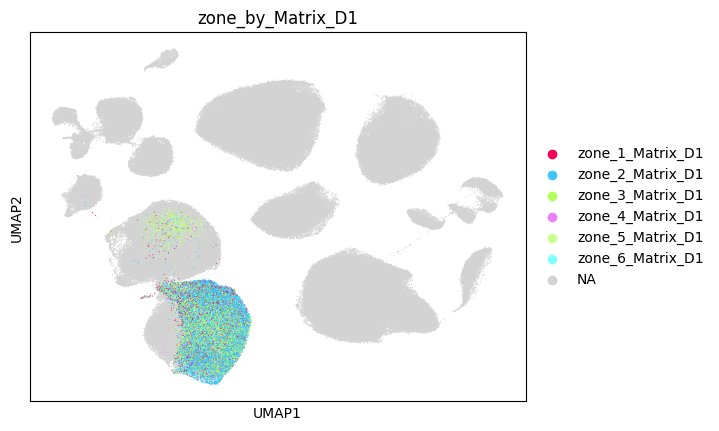

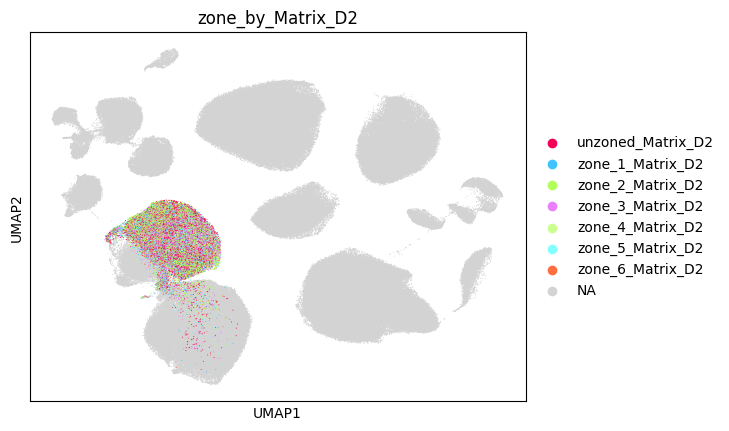

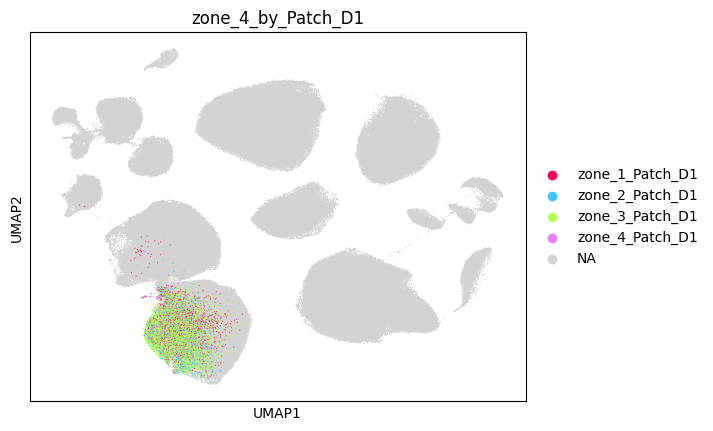

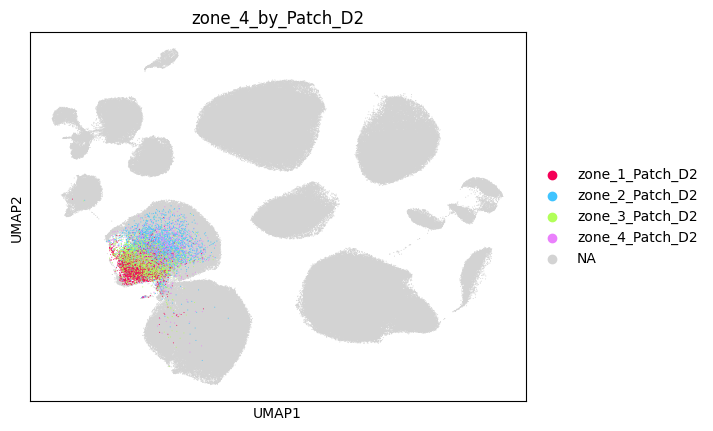

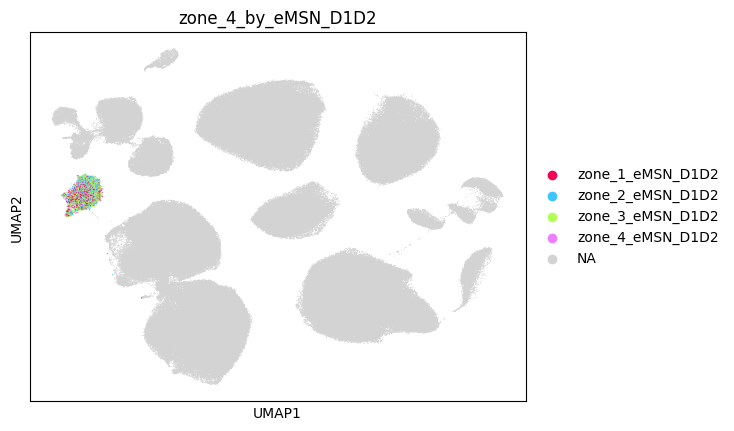

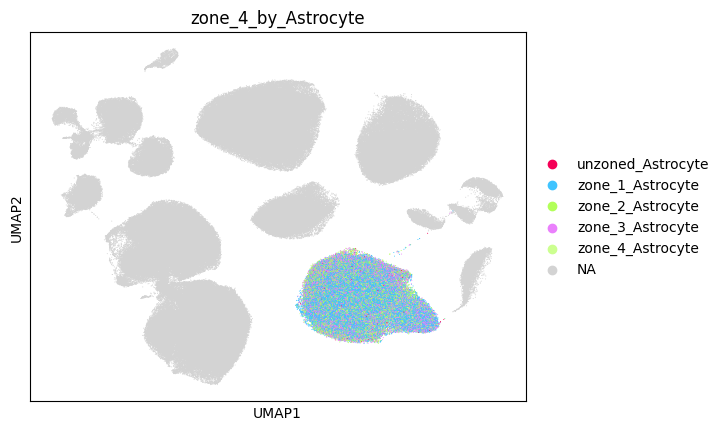

In [20]:
# How many cells of each zonable type actually got a zone
for zone_ct, zone_variable in ZONE_CT_MAP.items():
    z = adata.obs.loc[adata.obs[CT_COL] == zone_ct, zone_variable]
    print(f"{zone_ct:10s} ({zone_variable}): {z.notna().sum():6d} zoned, {z.isna().sum():6d} unzoned")

zone_split_cols = []
for zone_ct, zone_variable in ZONE_CT_MAP.items():
    zone_col = f"{zone_variable}_by_{zone_ct}"
    adata.obs[zone_col] = pd.Categorical(split_by_zone(adata.obs[CT_COL], adata.obs, zone_ct, zone_variable))
    zone_split_cols.append(zone_col)

    # UMAP: highlight only the relabelled cells of this cell type
    relabelled = [c for c in adata.obs[zone_col].cat.categories if c.endswith("_" + zone_ct)]
    sc.pl.umap(adata, color=zone_col, groups=relabelled, size=2, title=zone_col,
               palette=preprocessing.custom_palette)

### A.2 Run crumblr (all cells)

In [21]:
LEVELS_ALL = [CT_COL, *zone_split_cols, *ATLAS_LEVELS]
print("Annotation levels:", LEVELS_ALL)

df_all = run_crumblr_grid(adata, LEVELS_ALL, out_dir=f"{SAVE_FOLDER}/all_cells")
df_all[df_all["coefficient"].str.contains(CONTRAST_STIM)].sort_values("adj.P.Val").head(20)

Annotation levels: ['ct_for_deg', 'zone_by_Matrix_D1', 'zone_by_Matrix_D2', 'zone_4_by_Patch_D1', 'zone_4_by_Patch_D2', 'zone_4_by_eMSN_D1D2', 'zone_4_by_Astrocyte', 'Class_name', 'Subclass_name', 'Group_name']

HD Handsaker (village) | ct_for_deg


racting results ──────────────────────────────────────────────────
  Test coefficients: StatusCase 
── Generating R plots ──────────────────────────────────────────────────
── Done.  Results written to /home/gdallagl/myworkdir/data/HD_Handsaker/compositional/crumblr/all_cells/ct_for_deg
[5/6] Generating plots …
  Saved: composition_bar.{pdf,png}
  Saved: cell_class_summary.{pdf,png}
  Saved: proportion_boxplots.{pdf,png}
  Saved: clr_heatmap.{pdf,png}
  Saved: volcano_StatusCase.{pdf,png}
  Saved: logfc_bar_StatusCase.{pdf,png}
[6/6] Summary

  Significant cell types (FDR < 0.05): 21
              cell_type     logFC    adj.P.Val coefficient
              eMSN_D1D2 -1.816792 2.929272e-16  StatusCase
               Patch_D2 -1.455699 3.882496e-15  StatusCase
          eMSN_StrioMat -1.505820 3.972188e-14  StatusCase
            Macrophages  1.154731 6.381968e-13  StatusCase
          STR TAC3 GABA  0.656072 1.292354e-11  StatusCase
               Patch_D1 -1.146464 4.488321e-11  StatusC

,logFC,AveExpr,t,P.Value,adj.P.Val,B,cell_type,coefficient,annotation
155,-1.675677,0.030342,-11.120154,9.219671e-19,2.858098e-17,32.104460,zone_3_Patch_D2,StatusCase,zone_4_by_Patch_D2
24,-1.816792,0.145388,-10.617214,1.046169e-17,2.929272e-16,29.715683,eMSN_D1D2,StatusCase,ct_for_deg
211,-1.865192,0.055671,-10.590050,1.099051e-17,3.516962e-16,29.664809,eMSN_D1D2,StatusCase,zone_4_by_Astrocyte
278,-1.467726,1.242355,-10.285409,5.875267e-17,1.010380e-15,28.024499,STRd D2 Striosome MSN,StatusCase,Group_name
266,-1.809911,0.395197,-10.283018,5.943413e-17,1.010380e-15,28.014958,STR D1D2 Hybrid MSN,StatusCase,Group_name
222,-1.709162,2.330093,-9.988781,2.491628e-16,2.242466e-15,26.607463,CN LGE GABA,StatusCase,Class_name
203,-1.510942,0.913408,-10.062542,1.432201e-16,2.291521e-15,27.113166,Patch_D2,StatusCase,zone_4_by_Astrocyte
110,-1.368533,1.126103,-10.023993,1.932643e-16,2.995596e-15,26.845649,Patch_D2,StatusCase,zone_4_by_Patch_D1
118,-1.719852,0.268365,-10.139244,1.105351e-16,2.995596e-15,27.401979,eMSN_D1D2,StatusCase,zone_4_by_Patch_D1
149,-1.673730,0.251156,-9.977161,2.324081e-16,3.602326e-15,26.617249,eMSN_D1D2,StatusCase,zone_4_by_Patch_D2


## B. Neurons only

Same as A, but only neurons (`is_neuron == True`) are used, so the composition is *within the neuronal compartment*.
Glial changes (e.g. astrocytosis) then cannot shift the neuronal CLR values.

In [22]:
adata_n = adata[adata.obs["is_neuron"]].copy()
print(f"{adata_n.n_obs} neurons")

LEVELS_NEURONS = [CT_COL, *ATLAS_LEVELS]
print("Annotation levels:", LEVELS_NEURONS)

df_neurons = run_crumblr_grid(adata_n, LEVELS_NEURONS, out_dir=f"{SAVE_FOLDER}/only_neurons")
del adata_n
df_neurons[df_neurons["coefficient"].str.contains(CONTRAST_STIM)].sort_values("adj.P.Val").head(20)

192317 neurons
Annotation levels: ['ct_for_deg', 'Class_name', 'Subclass_name', 'Group_name']

HD Handsaker (village) | ct_for_deg
ing data ────────────────────────────────────────────────────────
  Samples: 96  |  Cell types: 16
  Formula: ~ Status + Sex + Age + village
  Contrast variable: Status
  Reference level: Control
── Running crumblr ─────────────────────────────────────────────────────
── Fitting dream model ─────────────────────────────────────────────────
── Extracting results ──────────────────────────────────────────────────
  Test coefficients: StatusCase 
── Generating R plots ──────────────────────────────────────────────────
── Done.  Results written to /home/gdallagl/myworkdir/data/HD_Handsaker/compositional/crumblr/only_neurons/ct_for_deg
[5/6] Generating plots …
  Saved: composition_bar.{pdf,png}
  Saved: cell_class_summary.{pdf,png}
  Saved: proportion_boxplots.{pdf,png}
  Saved: clr_heatmap.{pdf,png}
  Saved: volcano_StatusCase.{pdf,png}
  Saved: logfc_bar_Statu

,logFC,AveExpr,t,P.Value,adj.P.Val,B,cell_type,coefficient,annotation
12,-1.472509,0.402474,-10.123370,7.768238e-17,1.242918e-15,27.734696,eMSN_D1D2,StatusCase,ct_for_deg
10,0.973698,1.374668,9.249962,5.894273e-15,4.715419e-14,23.526593,STR TAC3 GABA,StatusCase,ct_for_deg
17,-1.591341,3.560296,-9.085471,1.958887e-14,9.794435e-14,22.335915,CN LGE GABA,StatusCase,Class_name
35,-1.433394,0.688732,-9.196563,1.110653e-14,1.864579e-13,22.889154,STR D1D2 Hybrid MSN,StatusCase,Group_name
40,0.983626,1.542905,9.089685,1.864579e-14,1.864579e-13,22.445247,STR TAC3-PLPP4 GABA,StatusCase,Group_name
47,-1.092701,1.544715,-8.708051,1.183321e-13,5.916606e-13,20.548683,STRd D2 Striosome MSN,StatusCase,Group_name
36,1.044145,1.728059,8.723085,1.100341e-13,5.916606e-13,20.696872,STR FS PTHLH-PVALB GABA,StatusCase,Group_name
6,-1.098784,1.269145,-8.464395,2.857243e-13,1.142897e-12,19.599501,Patch_D2,StatusCase,ct_for_deg
7,1.002528,1.465930,8.501630,2.378871e-13,1.142897e-12,19.859033,STR FS PTHLH-PVALB GABA,StatusCase,ct_for_deg
14,-1.246422,-1.394114,-8.355137,4.888732e-13,1.564394e-12,19.150108,eMSN_StrioMat,StatusCase,ct_for_deg


## C. All cells, all zonable types split by zone in one run

Section A.1 splits one cell type per run. Here **all** zonable cell types are split at the same time in a single column, `ct_all_zoned`.
Every zone of every zonable type is then tested against the same reference composition.
Non-zonable types keep their `ct_for_deg` label. Unzoned cells stay in as `unzoned_<ct>`, so no cell is dropped.

In [23]:
adata.obs["ct_all_zoned"] = adata.obs[CT_COL].astype(str)
for zone_ct, zone_variable in ZONE_CT_MAP.items():
    adata.obs["ct_all_zoned"] = split_by_zone(adata.obs["ct_all_zoned"], adata.obs, zone_ct, zone_variable)

print(adata.obs["ct_all_zoned"].value_counts().to_string())

out_dir = f"{SAVE_FOLDER}/all_cells_unified_zones"
df_unified = run_crumblr(filter_rare_categories(adata, "ct_all_zoned"), "ct_all_zoned", out_dir,
                         label=f"{DATASET_LABEL} | all CTs with zones (unified)")
df_unified["annotation"] = "ct_all_zoned"
df_unified.to_csv(f"{out_dir}/results.csv", index=False)
df_unified[df_unified["coefficient"].str.contains(CONTRAST_STIM)].sort_values("adj.P.Val").head(20)

ct_all_zoned
Oligodendrocyte            99841
zone_1_Astrocyte           48162
Microglia                  33609
zone_3_Astrocyte           31050
zone_2_Astrocyte           28978
OPC                        28574
zone_2_Matrix_D1           26707
zone_2_Matrix_D2           15534
zone_3_Matrix_D1           14487
unzoned_Matrix_D2          11180
STR FS PTHLH-PVALB GABA    11163
zone_3_Matrix_D2           11135
zone_3_Patch_D1            10737
STR TAC3 GABA               9658
zone_4_Astrocyte            8680
zone_5_Matrix_D1            8671
zone_1_Matrix_D1            8186
zone_1_Matrix_D2            7917
zone_5_Matrix_D2            5878
zone_6_Matrix_D1            5254
zone_3_Patch_D2             5150
Ependymal                   4740
zone_6_Matrix_D2            4392
Fibroblasts                 3201
zone_1_Patch_D2             3067
zone_2_Patch_D2             2927
zone_3_eMSN_D1D2            2835
Endothelial_BBB             2593
zone_4_Patch_D1             2507
zone_1_Patch_D1             24

,logFC,AveExpr,t,P.Value,adj.P.Val,B,cell_type,coefficient,annotation
8,1.571385,-0.239096,9.489262,2.555137e-15,4.428905e-14,24.356275,Macrophages,StatusCase,ct_all_zoned
16,1.030620,1.522431,9.500600,2.418076e-15,4.428905e-14,24.435639,STR TAC3 GABA,StatusCase,ct_all_zoned
40,-1.427322,0.316793,-9.528697,2.109293e-15,4.428905e-14,24.511941,zone_3_Patch_D2,StatusCase,ct_all_zoned
24,1.527724,2.947646,9.214589,9.714951e-15,1.262944e-13,23.101235,zone_1_Astrocyte,StatusCase,ct_all_zoned
6,1.296891,0.498158,8.553025,2.409361e-13,2.505735e-12,19.972715,Fibroblasts,StatusCase,ct_all_zoned
9,1.148075,2.703068,8.392415,5.239047e-13,4.540507e-12,19.112425,Microglia,StatusCase,ct_all_zoned
13,1.088312,1.606693,8.293321,8.453680e-13,6.279877e-12,18.623646,STR FS PTHLH-PVALB GABA,StatusCase,ct_all_zoned
42,1.460133,1.324616,8.147210,1.709520e-12,1.111188e-11,17.982019,zone_4_Astrocyte,StatusCase,ct_all_zoned
11,1.023120,3.845695,7.809260,8.653371e-12,4.999725e-11,16.397461,Oligodendrocyte,StatusCase,ct_all_zoned
4,0.989809,0.275558,7.451514,4.752100e-11,2.471092e-10,14.775670,Endothelial_BBB,StatusCase,ct_all_zoned


## D. Zones within each zonable cell type

Only the cells of **one** zonable cell type are used at a time. Unzoned cells are dropped and the categories are its zones (`zone_1`, `zone_2`, …).
The question is different from A/C: *within this cell type, does the distribution across zones shift in Case?*
For example, are the zone_1 Matrix_D1 cells lost relative to the other Matrix_D1 cells?

In [24]:
df_zones_list = []
for zone_ct, zone_variable in ZONE_CT_MAP.items():
    print(f"\n{'=' * 60}\n{zone_variable} | {zone_ct}")

    # only this cell type, only cells with a zone
    sub = adata[(adata.obs[CT_COL] == zone_ct) & adata.obs[zone_variable].notna()].copy()
    sub.obs["zone_labeled"] = "zone_" + sub.obs[zone_variable].astype(str)   # "zone_1": R would read a bare "1" as a number
    print(sub.obs["zone_labeled"].value_counts().sort_index().to_string())

    out_dir = f"{SAVE_FOLDER}/only_zone/{zone_variable}/{zone_ct}"
    try:
        df = run_crumblr(filter_rare_categories(sub, "zone_labeled"), "zone_labeled", out_dir,
                         label=f"{DATASET_LABEL} | {zone_variable} | {zone_ct}")
    except RuntimeError as e:
        print(f"  skipping (crumblr failed): {e}")
        continue
    df["ct_used_for_zoning"] = zone_ct
    df["zone_col"]           = zone_variable
    df_zones_list.append(df)

df_zones_per_ct = pd.concat(df_zones_list, ignore_index=True)
df_zones_per_ct["annotation"] = df_zones_per_ct["zone_col"]
df_zones_per_ct.to_csv(f"{SAVE_FOLDER}/only_zone/all_results.csv", index=False)
df_zones_per_ct[df_zones_per_ct["coefficient"].str.contains(CONTRAST_STIM)].sort_values("adj.P.Val")


zone | Matrix_D1
zone_labeled
zone_1     8186
zone_2    26707
zone_3    14487
zone_4     2457
zone_5     8671
zone_6     5254
[1/6] Loading /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/compositional/crumblr/only_zone/zone/Matrix_D1/cells.csv …
[2/6] Aggregating cell counts …
  Dropping 7 sample(s) with < 30 cells: ['S04105', 'S04374', 'S04827', 'S13264', 'S14251', 'S15563', 'S15755']
  Contrast 'Status' detected as categorical.
  Samples: 88  |  Cell types: 6
[3/6] Formula: ~ Status + Sex + Age + village
[4/6] Running crumblr (R) …

[R] /home/gdallagl/myworkdir/XDP/data/crumblr/micromamba_root/envs/crumblr/bin/Rscript … formula='~ Status + Sex + Age + village'
── Loading data ────────────────────────────────────────────────────────
  Samples: 88  |  Cell types: 6
  Formula: ~ Status + Sex + Age + village
  Contrast variable: Status
  Reference level: Control
── Running crumblr ─────────────────────────────────────────────────────
── Fitting dream model ──────────────────────────────

,logFC,AveExpr,t,P.Value,adj.P.Val,B,cell_type,coefficient,ct_used_for_zoning,zone_col,annotation
9,1.761425,-1.670101,4.582584,0.000016,0.000099,2.712434,zone_4,StatusCase,Matrix_D2,zone,zone
25,-0.394786,0.239408,-3.960242,0.000091,0.000363,1.101594,zone_2,StatusCase,Astrocyte,zone_4,zone_4
3,1.498406,-1.825978,4.192760,0.000065,0.000391,1.459991,zone_4,StatusCase,Matrix_D1,zone,zone
16,0.540965,0.125602,3.719815,0.000383,0.000957,-0.095015,zone_1,StatusCase,Patch_D2,zone_4,zone_4
19,0.718244,-0.497234,3.652738,0.000478,0.000957,-0.358033,zone_4,StatusCase,Patch_D2,zone_4,zone_4
10,1.467431,-0.526156,3.650379,0.000463,0.001388,-0.433939,zone_5,StatusCase,Matrix_D2,zone,zone
24,0.355600,0.592726,3.336716,0.000938,0.001409,-0.991761,zone_1,StatusCase,Astrocyte,zone_4,zone_4
26,-0.337256,0.198170,-3.302443,0.001057,0.001409,-1.139072,zone_3,StatusCase,Astrocyte,zone_4,zone_4
12,0.798875,-0.654188,3.233539,0.001760,0.007042,-1.401881,zone_1,StatusCase,Patch_D1,zone_4,zone_4
13,-0.597623,-0.426705,-2.521667,0.013609,0.027217,-3.112332,zone_2,StatusCase,Patch_D1,zone_4,zone_4


## E. Summary volcano plots

Only the `StatusCase` coefficient is shown. A point is highlighted when `FDR < FDR_THR` and `|logFC| > LFC_THR`.
FDR values come from the individual runs (BH within each run) and are **not** re-corrected across runs.

In [25]:
MARKERS = {CT_COL: "o", "Class_name": "s", "Subclass_name": "^", "Group_name": "D"}   # marker per annotation level

# colorblind-safe categorical palette (fixed order)
PALETTE   = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK       = "#0b0b0b"
MUTED_INK = "#52514e"
GRIDLINE  = "#c3c2b7"
MAX_LABELS = 15            # per colour group, only the most significant hits get a text label

FS_TICK, FS_POINT, FS_AXIS, FS_SUB, FS_TITLE, FS_LEGEND, FS_LEG_TITLE = 13, 10, 15, 13, 20, 11, 13

NICE_NAMES = {CT_COL: "Cell type", "Class_name": "Class", "Subclass_name": "Subclass", "Group_name": "Group"}


def pretty(label):
    """Readable label: known column names → nice names; strip 'zone_4_by_' / 'zone_by_'; '_' → ' '."""
    s = str(label)
    if s in NICE_NAMES:
        return NICE_NAMES[s]
    s = re.sub(r"^zone_4_by_", "", s)
    s = re.sub(r"^zone_by_",   "", s)
    return s.replace("_", " ")


def volcano(df, title, subtitle, save_path, color_col="annotation", label_col="cell_type", force_label=None,
            figsize=(10, 7.5)):
    """Volcano of the StatusCase coefficient, one colour per value of `color_col`."""
    df = df[df["coefficient"].str.contains(CONTRAST_STIM, na=False)].copy()
    df["-logFDR"] = -np.log10(df["adj.P.Val"].clip(1e-15))
    df = df[np.isfinite(df["logFC"]) & np.isfinite(df["-logFDR"])].copy()
    df["sig"] = (df["adj.P.Val"] < FDR_THR) & (df["logFC"].abs() > LFC_THR)

    groups = sorted(df[color_col].unique())
    if len(groups) > len(PALETTE):
        print(f"WARNING: {len(groups)} groups but only {len(PALETTE)} colours — some will repeat.")
    colors = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(groups)}

    fig, ax = plt.subplots(figsize=figsize)
    ax.axhline(-np.log10(FDR_THR), color=GRIDLINE, lw=0.8, ls="--", zorder=0)
    for x in (LFC_THR, -LFC_THR):
        ax.axvline(x, color=GRIDLINE, lw=0.8, ls="--", zorder=0)
    ax.axvline(0, color="#e1e0d9", lw=0.6, zorder=0)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color(GRIDLINE)
    ax.tick_params(colors=MUTED_INK, labelsize=FS_TICK)

    texts = []
    for g, grp in df.groupby(color_col):
        c, mk = colors[g], MARKERS.get(g, "o")
        ns, sig = grp[~grp["sig"]], grp[grp["sig"]]
        ax.scatter(ns["logFC"], ns["-logFDR"], s=15, marker=mk, color=c, alpha=0.25, edgecolors="none", zorder=2)
        ax.scatter(sig["logFC"], sig["-logFDR"], s=55, marker=mk, color=c, alpha=0.95,
                   edgecolors="white", linewidths=0.6, zorder=3, label=pretty(g))

        to_label = sig.sort_values("-logFDR", ascending=False).head(MAX_LABELS)
        if force_label:
            to_label = pd.concat([to_label, grp[grp[label_col].isin(force_label) & ~grp.index.isin(to_label.index)]])
        for _, r in to_label.iterrows():
            texts.append(ax.text(r["logFC"], r["-logFDR"], pretty(r[label_col]), fontsize=FS_POINT, color=INK,
                                 fontweight="semibold", zorder=4,
                                 path_effects=[pe.withStroke(linewidth=2, foreground="white")]))

    if texts:
        try:
            adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="#aaa", lw=0.5),
                        expand=(1.6, 1.9), force_text=(0.9, 1.1), force_static=(0.4, 0.6),
                        force_explode=(0.5, 0.8), max_move=(60, 60), iter_lim=600, time_lim=6, min_arrow_len=8)
        except Exception:
            traceback.print_exc()
            print("  adjustText crashed — labels are unshifted")

    ax.set_xlabel("log2FC (CLR)", fontsize=FS_AXIS, color=MUTED_INK)
    ax.set_ylabel("-log10(FDR)", fontsize=FS_AXIS, color=MUTED_INK)
    fig.suptitle(title, fontsize=FS_TITLE, fontweight="bold", color=INK, x=0.02, ha="left", y=0.985)
    ax.set_title(subtitle, fontsize=FS_SUB, color=MUTED_INK, loc="left", pad=10)
    handles, labels = ax.get_legend_handles_labels()
    seen = dict(zip(labels, handles))
    ax.legend(seen.values(), seen.keys(), title=pretty(color_col), fontsize=FS_LEGEND, title_fontsize=FS_LEG_TITLE,
              bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


SUBTITLE = f"{CONTRAST_STIM} vs. {CONTRAST_REF}  |  FDR < {FDR_THR}  |  |log2FC| > {LFC_THR}"

Both time_lim and iter_lim are set, faster will be used


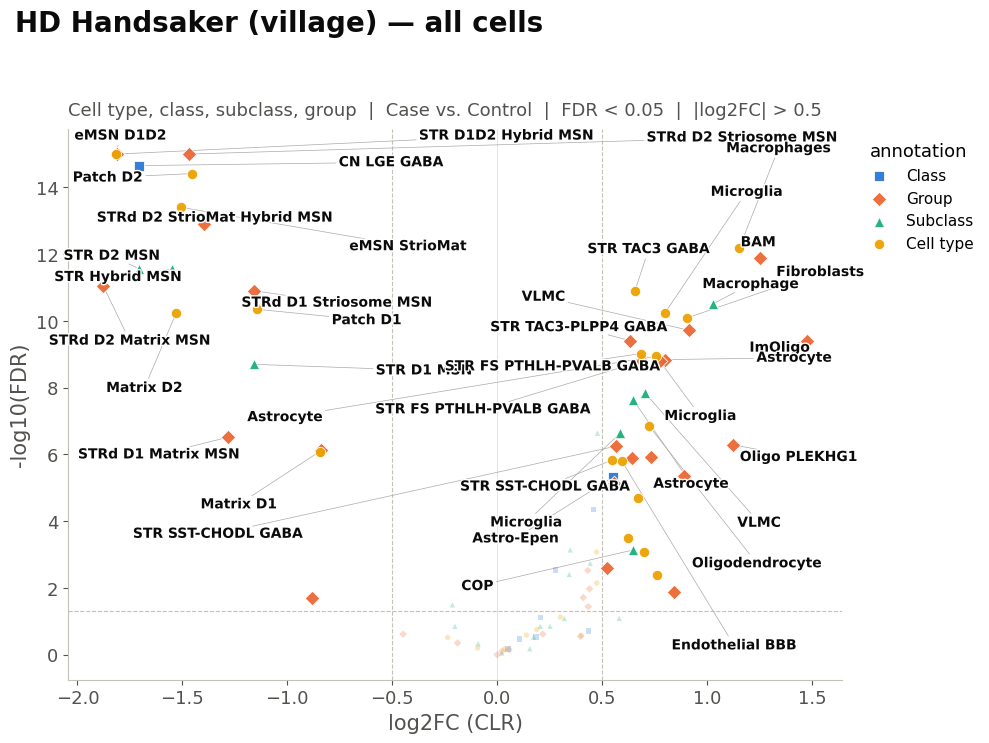

Both time_lim and iter_lim are set, faster will be used


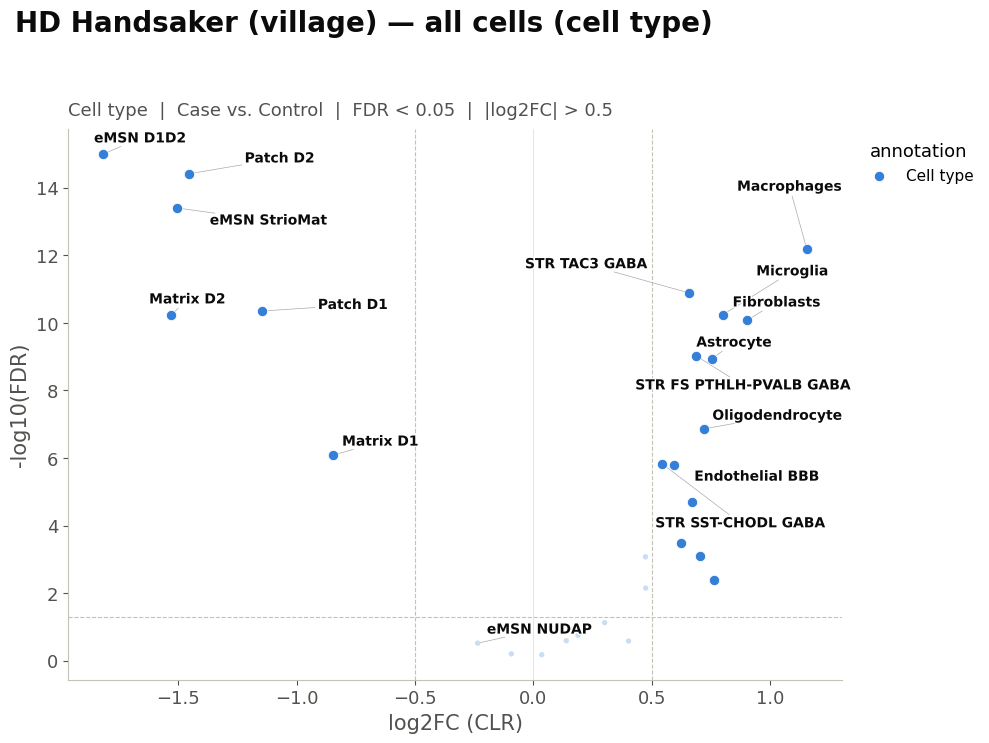

Both time_lim and iter_lim are set, faster will be used


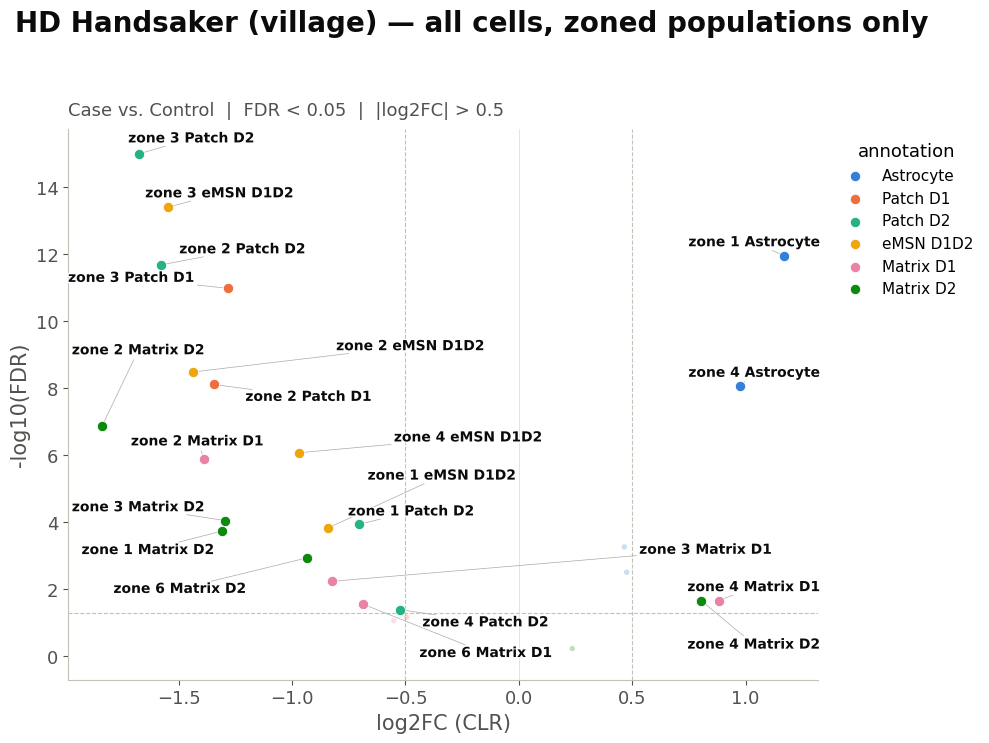

Both time_lim and iter_lim are set, faster will be used


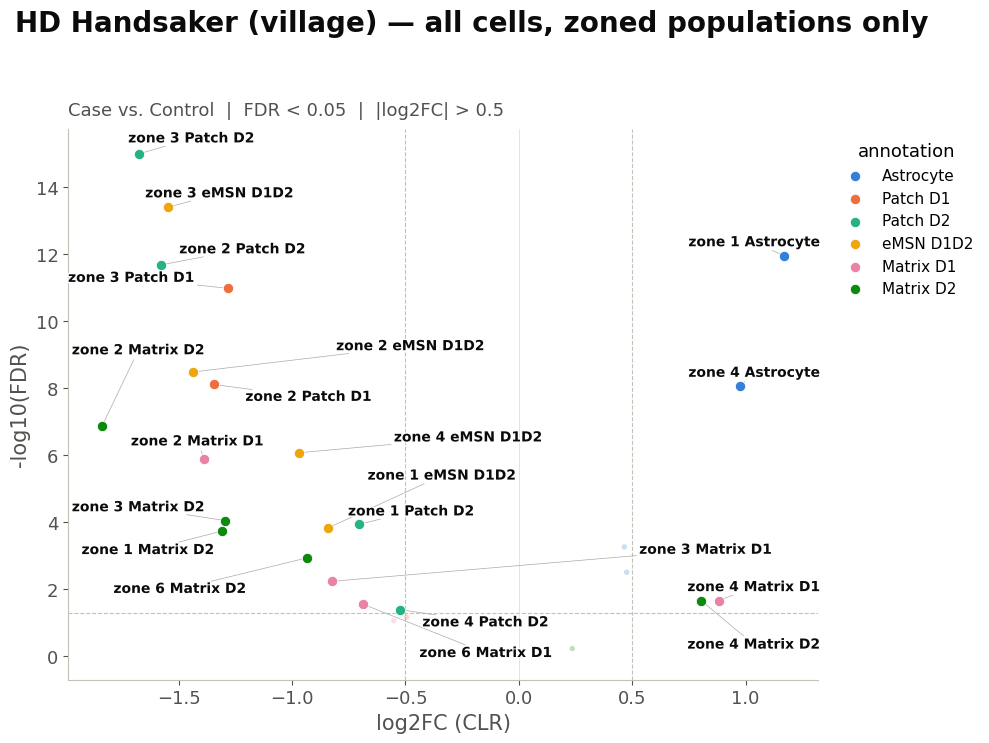

Both time_lim and iter_lim are set, faster will be used


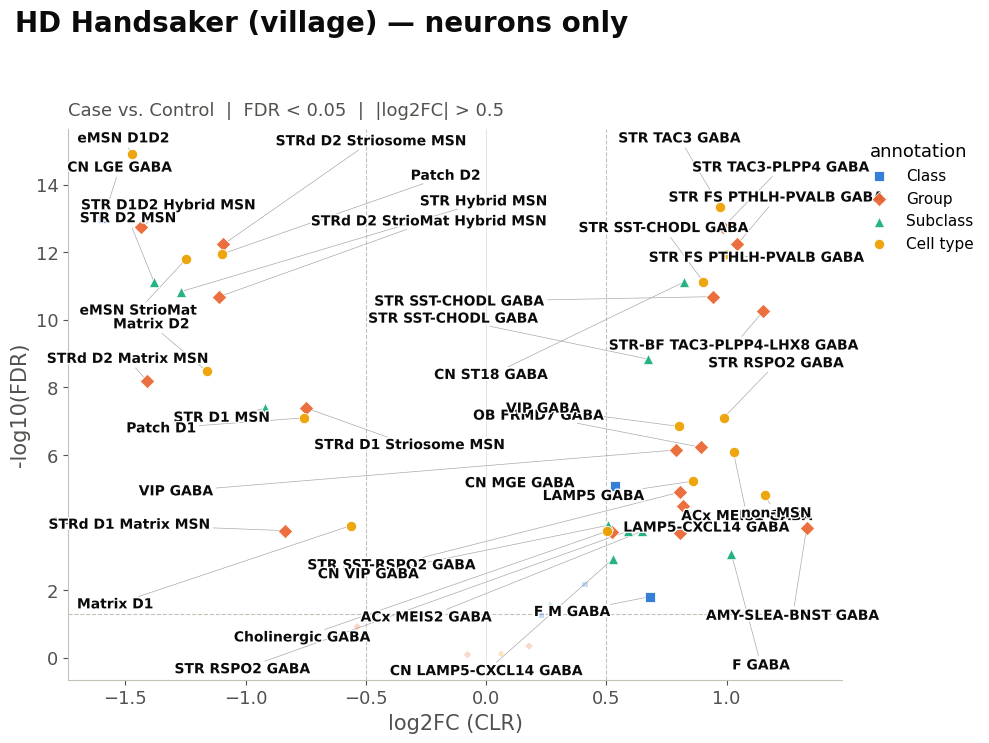

Both time_lim and iter_lim are set, faster will be used


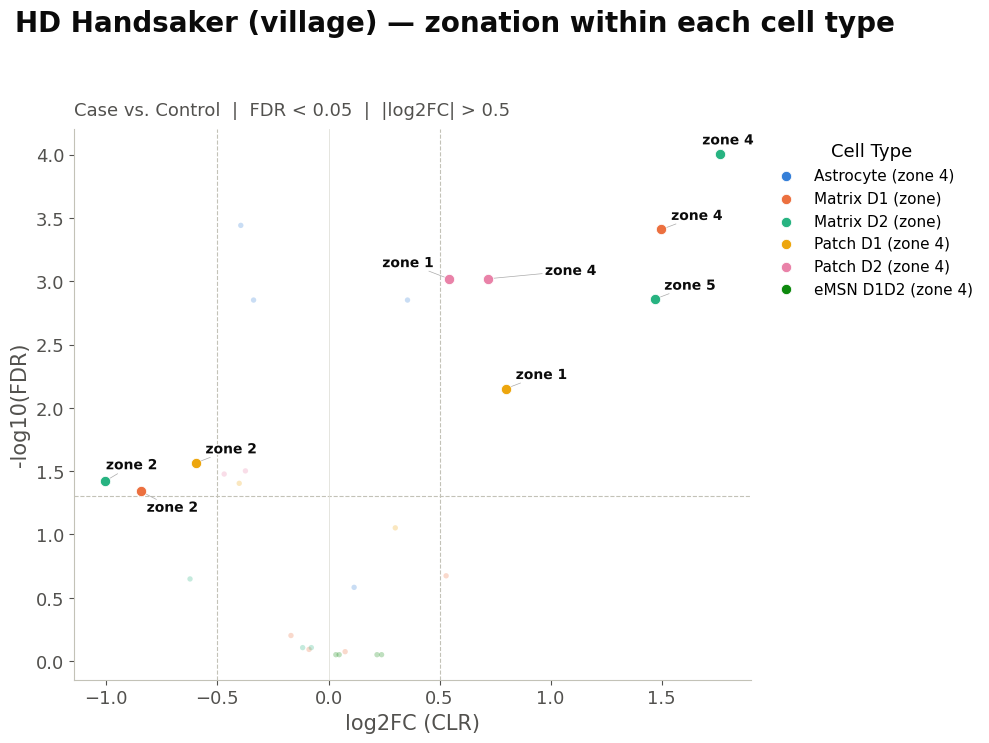

In [26]:
# results are re-read from disk so this section can be run without re-running A–D
df_all  = pd.read_csv(f"{SAVE_FOLDER}/all_cells/merged_results.csv")
df_neu  = pd.read_csv(f"{SAVE_FOLDER}/only_neurons/merged_results.csv")
df_zone = pd.read_csv(f"{SAVE_FOLDER}/only_zone/all_results.csv")
NON_ZONE        = [CT_COL, *ATLAS_LEVELS]
zone_split_cols = [f"{zv}_by_{ct}" for ct, zv in ZONE_CT_MAP.items()]   # same names as in A.1

# 1) all cells — ct_for_deg + atlas levels
volcano(df_all[df_all["annotation"].isin(NON_ZONE)],
        title=f"{DATASET_LABEL} — all cells", subtitle=f"Cell type, class, subclass, group  |  {SUBTITLE}",
        save_path=f"{SAVE_FOLDER}/all_cells/volcano_ct.png")

# 2) all cells — ct_for_deg only, with forced labels for the eMSN types
volcano(df_all[df_all["annotation"] == CT_COL],
        title=f"{DATASET_LABEL} — all cells (cell type)", subtitle=f"Cell type  |  {SUBTITLE}",
        save_path=f"{SAVE_FOLDER}/all_cells/volcano_ct_for_deg.png", force_label=FORCE_LABEL_CT)

# 3) all cells — zone-split runs (A.1): show only the zone categories, not the other cell types of those runs
zones = df_all[df_all["annotation"].isin(zone_split_cols) & df_all["cell_type"].str.match(r"^zone_\d+_")]
for ext in ("png", "pdf"):
    volcano(zones, title=f"{DATASET_LABEL} — all cells, zoned populations only", subtitle=SUBTITLE,
            save_path=f"{SAVE_FOLDER}/all_cells/volcano_zones_combined.{ext}")

# 4) neurons only
volcano(df_neu, title=f"{DATASET_LABEL} — neurons only", subtitle=SUBTITLE,
        save_path=f"{SAVE_FOLDER}/only_neurons/volcano_only_neurons.png")

# 5) zones within each zonable cell type (D)
df_zone["Cell Type"] = df_zone["ct_used_for_zoning"].map(pretty) + " (" + df_zone["zone_col"] + ")"
volcano(df_zone, title=f"{DATASET_LABEL} — zonation within each cell type", subtitle=SUBTITLE,
        color_col="Cell Type", save_path=f"{SAVE_FOLDER}/only_zone/volcano_zones_within_ct.png")